# VQ-VAE: A Single Discrete Latent Grid

A VQ-VAE maps an input to continuous encoder features, then replaces each feature vector with its nearest learned codebook embedding. The decoder receives the quantized grid. Unlike a standard VAE, this model uses discrete code indices and does not use a Gaussian posterior KL term.

## Quantization and objective

For encoder vector `z_e` and codebook vectors `e_k`, select `k* = argmin_k ||z_e - e_k||^2` and use `z_q = e_k*`. The nearest-code `argmin` is not differentiable, so the straight-through estimator uses `z_st = z_e + stop_gradient(z_q - z_e)`: forward values are quantized, while the reconstruction gradient is copied to the encoder as if the operation were the identity.

The loss is reconstruction BCE + codebook loss `||stopgrad(z_e)-z_q||²` + beta times commitment loss `||z_e-stopgrad(z_q)||²`. Codebook loss moves embeddings toward encoder outputs; commitment loss keeps encoder outputs near their assignments. Here beta is the commitment coefficient, not the Beta-VAE KL coefficient. This notebook uses a convolutional MNIST encoder and quantizes each spatial location.

## Code usage and generation caveat

Track active codes, assignment frequency, and codebook perplexity, along with reconstruction quality. A large codebook can be underused, and VQ-VAE does not guarantee that the decoder uses every code. Random code indices are not samples from a learned image distribution; a separate prior (for example, an autoregressive model over code tokens) is needed for meaningful unconditional generation. This notebook visualizes reconstructions and learned code assignments.

In [1]:
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device

device(type='cuda')

In [2]:
transform = transforms.ToTensor()
train_data = datasets.MNIST('data', train=True, download=True, transform=transform)
test_data = datasets.MNIST('data', train=False, download=True, transform=transform)
train_loader = DataLoader(train_data, batch_size=128, shuffle=True)
test_loader = DataLoader(test_data, batch_size=128, shuffle=False)

## Build the encoder, vector quantizer, and decoder

The encoder produces a 7×7 feature grid. Each grid position independently selects one of the learned embeddings. The decoder maps the quantized feature grid back to a 28×28 image.

In [3]:
class VectorQuantizer(nn.Module):
    def __init__(self, num_codes=128, code_dim=64, commitment_beta=0.25):
        super().__init__()
        self.embedding = nn.Embedding(num_codes, code_dim)
        nn.init.uniform_(self.embedding.weight, -1 / num_codes, 1 / num_codes)
        self.commitment_beta = commitment_beta

    def forward(self, z_e):  # z_e: [B, D, H, W]
        b, d, h, w = z_e.shape
        vectors = z_e.permute(0, 2, 3, 1).contiguous()
        flat = vectors.view(-1, d)
        # Squared Euclidean distances, without materializing [vectors, codes, dims].
        distances = flat.square().sum(1, keepdim=True) + self.embedding.weight.square().sum(1) - 2 * flat @ self.embedding.weight.t()
        indices = distances.argmin(dim=1)
        z_q = self.embedding(indices).view(b, h, w, d)
        codebook_loss = F.mse_loss(z_q, vectors.detach())
        commitment_loss = F.mse_loss(vectors, z_q.detach())
        quantizer_loss = codebook_loss + self.commitment_beta * commitment_loss
        z_st = vectors + (z_q - vectors).detach()
        counts = torch.bincount(indices, minlength=self.embedding.num_embeddings).float()
        probs = counts / counts.sum().clamp_min(1)
        perplexity = torch.exp(-(probs * torch.log(probs + 1e-10)).sum())
        return z_st.permute(0, 3, 1, 2).contiguous(), quantizer_loss, indices.view(b, h, w), perplexity

class VQVAE(nn.Module):
    def __init__(self, num_codes=128, code_dim=64):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 32, 4, stride=2, padding=1), nn.ReLU(),
            nn.Conv2d(32, code_dim, 4, stride=2, padding=1))
        self.quantizer = VectorQuantizer(num_codes, code_dim)
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(code_dim, 32, 4, stride=2, padding=1), nn.ReLU(),
            nn.ConvTranspose2d(32, 1, 4, stride=2, padding=1), nn.Sigmoid())

    def forward(self, x):
        z_e = self.encoder(x)
        z_q, vq_loss, indices, perplexity = self.quantizer(z_e)
        return self.decoder(z_q), vq_loss, indices, perplexity

model = VQVAE().to(device)

## Train the VQ-VAE

The straight-through path carries reconstruction gradients to the encoder. The codebook and commitment terms update the embedding vectors and encoder respectively. We log codebook perplexity to observe effective code usage.

In [4]:
optimizer = torch.optim.Adam(model.parameters(), lr=2e-3)
def run_epoch(loader, training):
    model.train(training)
    totals = torch.zeros(3)
    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for x, _ in loader:
            x = x.to(device)
            if training: optimizer.zero_grad()
            reconstruction, vq_loss, _, perplexity = model(x)
            recon_loss = F.binary_cross_entropy(reconstruction, x)
            loss = recon_loss + vq_loss
            if training:
                loss.backward(); optimizer.step()
            totals += torch.tensor([loss.item(), recon_loss.item(), perplexity.item()]) * x.size(0)
    return (totals / len(loader.dataset)).tolist()

epochs = 50
history = []
for epoch in range(1, epochs + 1):
    metrics = run_epoch(train_loader, True)
    history.append(metrics)
    print(f'Epoch {epoch:02d} | total {metrics[0]:.4f} | reconstruction {metrics[1]:.4f} | mean batch perplexity {metrics[2]:.1f}')

Epoch 01 | total 0.8534 | reconstruction 0.1735 | mean batch perplexity 4.8
Epoch 02 | total 0.1708 | reconstruction 0.0890 | mean batch perplexity 11.1
Epoch 03 | total 0.1511 | reconstruction 0.0823 | mean batch perplexity 13.1
Epoch 04 | total 0.1352 | reconstruction 0.0786 | mean batch perplexity 14.4
Epoch 05 | total 0.1281 | reconstruction 0.0769 | mean batch perplexity 14.5
Epoch 06 | total 0.1266 | reconstruction 0.0760 | mean batch perplexity 14.5
Epoch 07 | total 0.1247 | reconstruction 0.0752 | mean batch perplexity 15.0
Epoch 08 | total 0.1226 | reconstruction 0.0745 | mean batch perplexity 15.3
Epoch 09 | total 0.1204 | reconstruction 0.0739 | mean batch perplexity 15.7
Epoch 10 | total 0.1190 | reconstruction 0.0733 | mean batch perplexity 16.0
Epoch 11 | total 0.1186 | reconstruction 0.0730 | mean batch perplexity 16.1
Epoch 12 | total 0.1188 | reconstruction 0.0727 | mean batch perplexity 16.0
Epoch 13 | total 0.1190 | reconstruction 0.0725 | mean batch perplexity 16.0


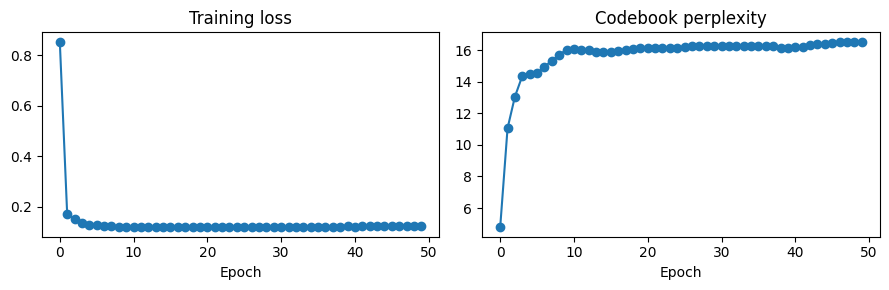

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].plot([m[0] for m in history], marker='o'); axes[0].set(title='Training loss', xlabel='Epoch')
axes[1].plot([m[2] for m in history], marker='o'); axes[1].set(title='Codebook perplexity', xlabel='Epoch')
plt.tight_layout(); plt.show()

## Inspect reconstructions and code assignments

Perplexity summarizes the effective number of codes used in a batch: low values suggest a few codes dominate. Also inspect assignment frequency and spatial code maps. No single utilization number is universally ideal.

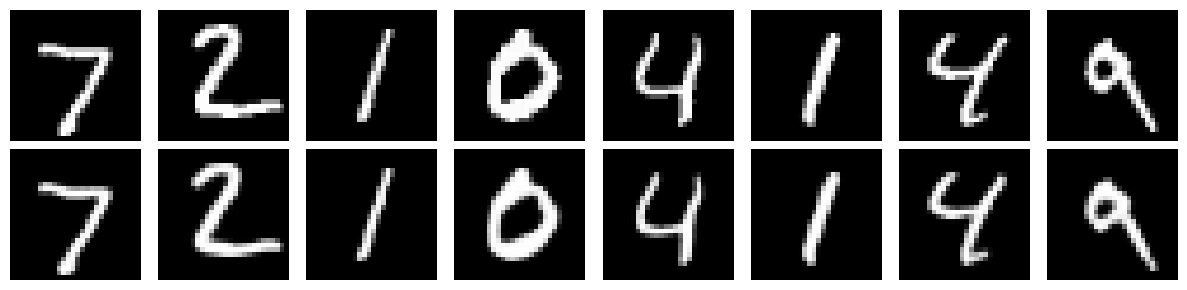

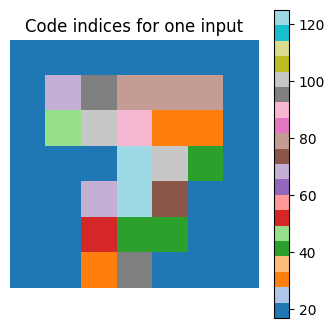

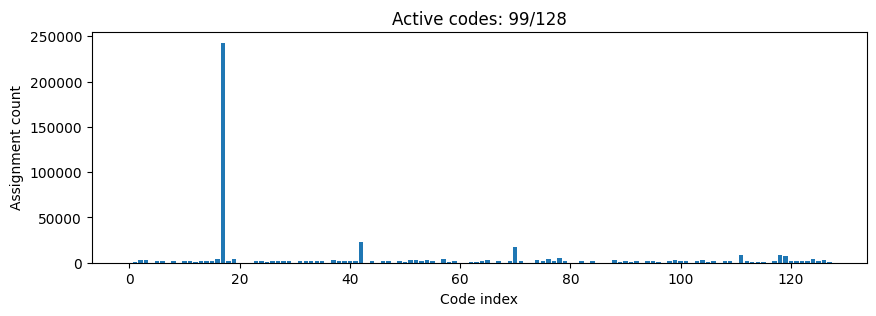

In [6]:
images, _ = next(iter(test_loader))
images = images[:8].to(device)
model.eval()
with torch.no_grad(): recon, _, indices, _ = model(images)
fig, axes = plt.subplots(2, 8, figsize=(12, 3))
for i in range(8):
    axes[0, i].imshow(images[i, 0].cpu(), cmap='gray'); axes[0, i].axis('off')
    axes[1, i].imshow(recon[i, 0].cpu(), cmap='gray'); axes[1, i].axis('off')
axes[0, 0].set_ylabel('Input'); axes[1, 0].set_ylabel('Reconstruction')
plt.tight_layout(); plt.show()

plt.figure(figsize=(4, 4)); plt.imshow(indices[0].cpu(), interpolation='nearest', cmap='tab20')
plt.title('Code indices for one input'); plt.colorbar(); plt.axis('off'); plt.show()

with torch.no_grad():
    all_indices = []
    for x, _ in test_loader:
        _, _, idx, _ = model(x.to(device))
        all_indices.append(idx.flatten().cpu())
counts = torch.bincount(torch.cat(all_indices), minlength=model.quantizer.embedding.num_embeddings)
active = (counts > 0).sum().item()
plt.figure(figsize=(10, 3)); plt.bar(range(len(counts)), counts.numpy())
plt.xlabel('Code index'); plt.ylabel('Assignment count'); plt.title(f'Active codes: {active}/{len(counts)}'); plt.show()

## Takeaways and knowledge check

VQ-VAE replaces each continuous encoder vector with its nearest codebook entry. The straight-through estimator approximates the gradient through discrete selection. Codebook loss moves embeddings toward encoder features; commitment loss keeps encoder features near the selected code. Codebook collapse and decoder underuse remain possible, even without the standard Gaussian KL penalty.

A VQ-VAE code grid can be flattened into discrete tokens for a separate prior model (such as a Transformer) to predict. The codebook provides the vocabulary; the prior learns token arrangements. A hierarchical extension such as VQ-VAE-2 uses multiple code grids for coarse and fine information.